# Mangrove Pulse: satellite evidence and inspection requests

**Team:** Taimaa Ghazal, Team Leader & Concept Development Lead; Salim Ammar, Technical Lead & Team Presenter.

Historical Khor Kalba satellite evidence → reference uncertainty → observation requests → conditional platform choice.

The saved run reproduces the frozen Sentinel-2/GMW baseline and audit, displays earlier reference-sensitivity results, checks request and blank-return metadata for 85 historical centres, and exports observation templates. It contains no collected field observations or aircraft missions.

Reference agreement is not field accuracy. The amphibious drone remains a concept. C001/C017 may need only dated imagery; current contact sensing needs a separate justified task and permission. Present observations cannot directly label 2018 cover.

This reading copy has revised Markdown and the unchanged code, inputs and outputs from the 7 October 2026 execution. It is not a new run. The [original execution record](Mangrove_Pulse_End_to_End_Executed.ipynb) and [provenance](docs/PROVENANCE.md) are preserved separately.


In [1]:
# Portable snapshot: no repeat dataset uploads.
import base64, io, zipfile, tempfile, hashlib
from pathlib import Path, PurePosixPath
SNAPSHOT_B64 = '...'
SNAPSHOT_SHA256 = '3a861ebc54c85dc3216c4ea799bc5e74cd6b6e51236ca97b1a94487096ece43c'
raw=base64.b64decode(SNAPSHOT_B64,validate=True)
if hashlib.sha256(raw).hexdigest()!=SNAPSHOT_SHA256: raise ValueError('Embedded snapshot hash mismatch')
container=Path(tempfile.mkdtemp(prefix='mp_portable_repository_'))
with zipfile.ZipFile(io.BytesIO(raw)) as archive:
    entries=archive.infolist()
    if len({i.filename for i in entries})!=len(entries): raise ValueError('Duplicate paths')
    if sum(i.file_size for i in entries)>100_000_000: raise ValueError('Snapshot too large')
    for entry in entries:
        p=PurePosixPath(entry.filename)
        if p.is_absolute() or '..' in p.parts or ':' in entry.filename or '\\' in entry.filename: raise ValueError('Unsafe path')
        if (entry.external_attr>>16)&0o170000==0o120000: raise ValueError('Symlink refused')
    if archive.testzip() is not None: raise ValueError('Snapshot CRC failure')
    archive.extractall(container)
roots=[p.parent for p in container.rglob('SHA256SUMS.json') if (p.parent/'src/run_submission.py').is_file()]
if len(roots)!=1: raise ValueError('Expected one repository')
EMBEDDED_REPO_ROOT=roots[0]
print('Portable repository verified:',SNAPSHOT_SHA256)
from pathlib import Path, PurePosixPath
import json, hashlib, os, sys, tempfile, subprocess, zipfile, traceback, platform
from datetime import datetime, timezone
from IPython.display import display, Markdown, Image

RUN = Path(tempfile.mkdtemp(prefix='mangrove_pulse_end_to_end_'))
STATE = {'status':'initializing', 'started_utc':datetime.now(timezone.utc).isoformat(),
         'reproduction':'not_run', 'handoff':'not_run', 'field_observations':0,
         'reference_context':'saved_prior_Colab_result_not_recomputed',
         'drone_energy':'saved_hypothetical_result_not_recomputed'}
def record():
    (RUN/'review_status.json').write_text(json.dumps(STATE,indent=2)+'\n')
def command(args, name, timeout=900, env=None, cwd=None):
    try:
        result = subprocess.run(args,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
                                text=True,timeout=timeout,env=env,cwd=cwd)
        text = result.stdout
        (RUN/(name+'.log')).write_text(text)
        print(text[-16000:])
        if result.returncode: raise RuntimeError(name+' failed; diagnostic log saved')
    except subprocess.TimeoutExpired as exc:
        raw=exc.stdout or b''
        text=raw.decode(errors='replace') if isinstance(raw,bytes) else raw
        (RUN/(name+'.log')).write_text(text+'\nTIMEOUT')
        raise
def extract_safe(raw, destination):
    with zipfile.ZipFile(raw) as z:
        entries=z.infolist()
        if len({i.filename for i in entries}) != len(entries): raise ValueError('Duplicate ZIP entries')
        if sum(i.file_size for i in entries)>100_000_000: raise ValueError('ZIP too large')
        for i in entries:
            p=PurePosixPath(i.filename)
            if '\\' in i.filename or p.is_absolute() or '..' in p.parts or ':' in i.filename:
                raise ValueError('Unsafe ZIP path')
            if (i.external_attr>>16)&0o170000 == 0o120000: raise ValueError('ZIP symlink refused')
        if z.testzip() is not None: raise ValueError('ZIP CRC failure')
        z.extractall(destination)
try:
    candidates=[Path.cwd(),Path('/content/mangrove-pulse'),Path('/content/submission')]
    if 'EMBEDDED_REPO_ROOT' in globals(): candidates.insert(0,EMBEDDED_REPO_ROOT)
    ROOT=next((p for p in candidates if (p/'SHA256SUMS.json').is_file() and (p/'src/run_submission.py').is_file()),None)
    if ROOT is None:
        from google.colab import files
        print('Slim version: upload the repository ZIP once; portable version needs no upload.')
        uploads=files.upload()
        if len(uploads)!=1: raise ValueError('Choose one repository ZIP')
        name,raw=next(iter(uploads.items()))
        archive=RUN/'repository.zip'; archive.write_bytes(raw)
        extract_safe(archive,RUN/'repository')
        roots=[p.parent for p in (RUN/'repository').rglob('SHA256SUMS.json') if (p.parent/'src/run_submission.py').is_file()]
        if len(roots)!=1: raise ValueError('Expected one repository root')
        ROOT=roots[0]
    ROOT=ROOT.resolve()
    manifest=json.loads((ROOT/'SHA256SUMS.json').read_text())
    for name,expected in manifest.items():
        p=(ROOT/name).resolve()
        if not p.is_relative_to(ROOT) or not p.is_file() or hashlib.sha256(p.read_bytes()).hexdigest()!=expected:
            raise ValueError('Missing/changed/unsafe packaged file: '+name)
    (RUN/'input_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
    STATE.update(status='inputs_verified',packaged_files_verified=len(manifest))
    print('INPUTS VERIFIED:',len(manifest),'files. Output:',RUN)
except Exception as exc:
    STATE.update(status='failed_inputs',error=str(exc))
    (RUN/'input_failure.log').write_text(traceback.format_exc())
    print('Inputs failed. Continue to the final diagnostic cell:',exc)
record()


Portable repository verified: 3a861ebc54c85dc3216c4ea799bc5e74cd6b6e51236ca97b1a94487096ece43c
INPUTS VERIFIED: 109 files. Output: /tmp/mangrove_pulse_end_to_end_fz8cmpr8


## 1. Reproduction environment

The run uses a separate environment with pinned requirements and Matplotlib's Agg backend. The embedded input snapshot preserves the files used for this execution. Installation requires internet; the analysis reuses cached data.


In [2]:
if STATE['status']=='inputs_verified':
    try:
        VENV=RUN/'venv'
        command([sys.executable,'-m','venv','--without-pip',str(VENV)],'create_environment',180)
        PY=VENV/('Scripts/python.exe' if os.name=='nt' else 'bin/python')
        command([sys.executable,'-m','pip','--python',str(PY),'install','--disable-pip-version-check',
                 '-r',str(ROOT/'requirements.txt')],'install_dependencies',900)
        ENV=os.environ.copy()
        ENV.update(MPLBACKEND='Agg',MPLCONFIGDIR=str(RUN/'mplconfig'),PYTHONDONTWRITEBYTECODE='1')
        STATE['status']='dependencies_ready'
        print('Isolated runtime ready; kernel unchanged.')
    except Exception as exc:
        STATE.update(status='failed_dependencies',error=str(exc))
        print('Installation failed; continue to final cell for diagnostics:',exc)
else: print('Installation skipped: inputs did not pass.')
record()



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.1/130.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 84.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.3/38.3 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 101.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 384.7/384.7 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 112.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 61.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 107.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22

## 2. Reproduce the frozen satellite experiment

The engines reproduce northern calibration and southern evaluation, separated by a 200 m gap, with threshold 0.49. That gap does not establish spatial independence. Both dates come from Sentinel-2; the second date is a repeatability check, not independent validation. The raw-DN red/NIR contrast is not presented as calibrated NDVI or a health index.

The runner compares summaries, decoded grids and predictions, audit rows and case memberships with saved records. This stage does not recompute the separate GMW/WorldCover comparison or hypothetical drone model.


Running reference_baseline.py
Running disagreement_audit.py
REPRODUCTION MATCHED. No independent ecological accuracy or new visual review established.



**RESULT: frozen baseline and audit reproduced and matched.** Not field accuracy.

| Southern reference agreement | Nov 20, 2018 | Nov 30, 2018 |
|---|---:|---:|
| Precision | 0.9094 | 0.9084 |
| Recall | 0.8645 | 0.8702 |
| F1 | 0.8864 | 0.8889 |
| IoU | 0.7960 | 0.8000 |

Northern calibration F1: 0.6652 — not regional generalization


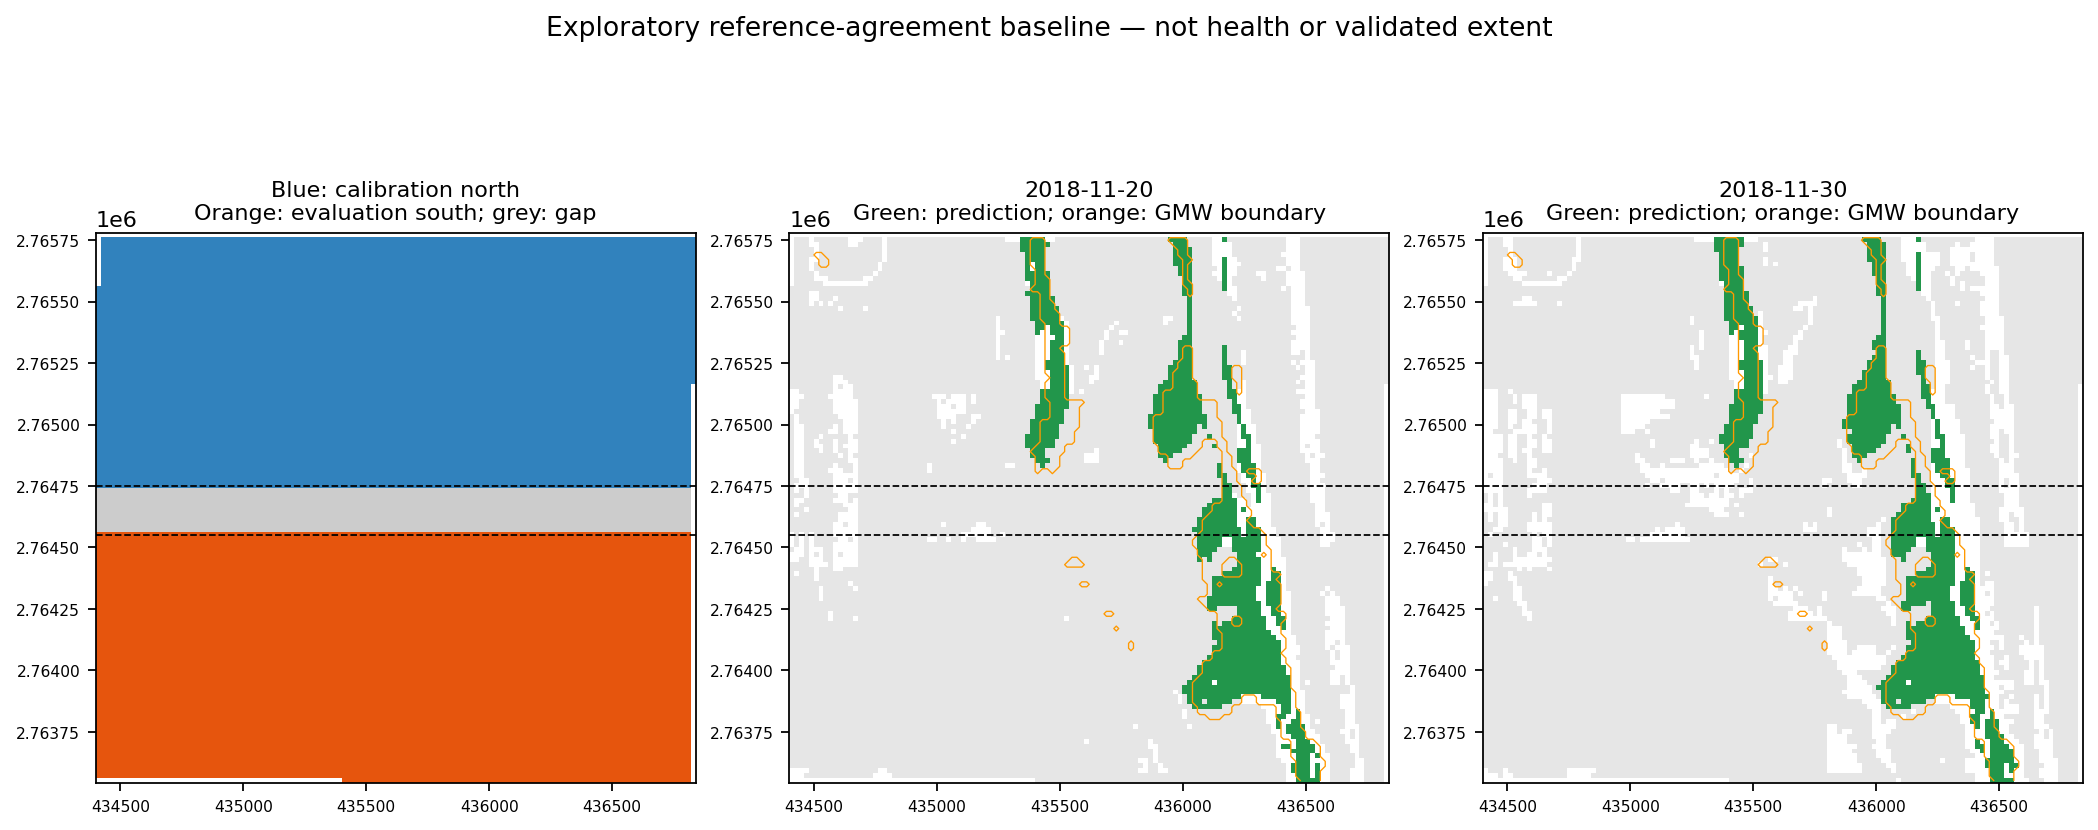

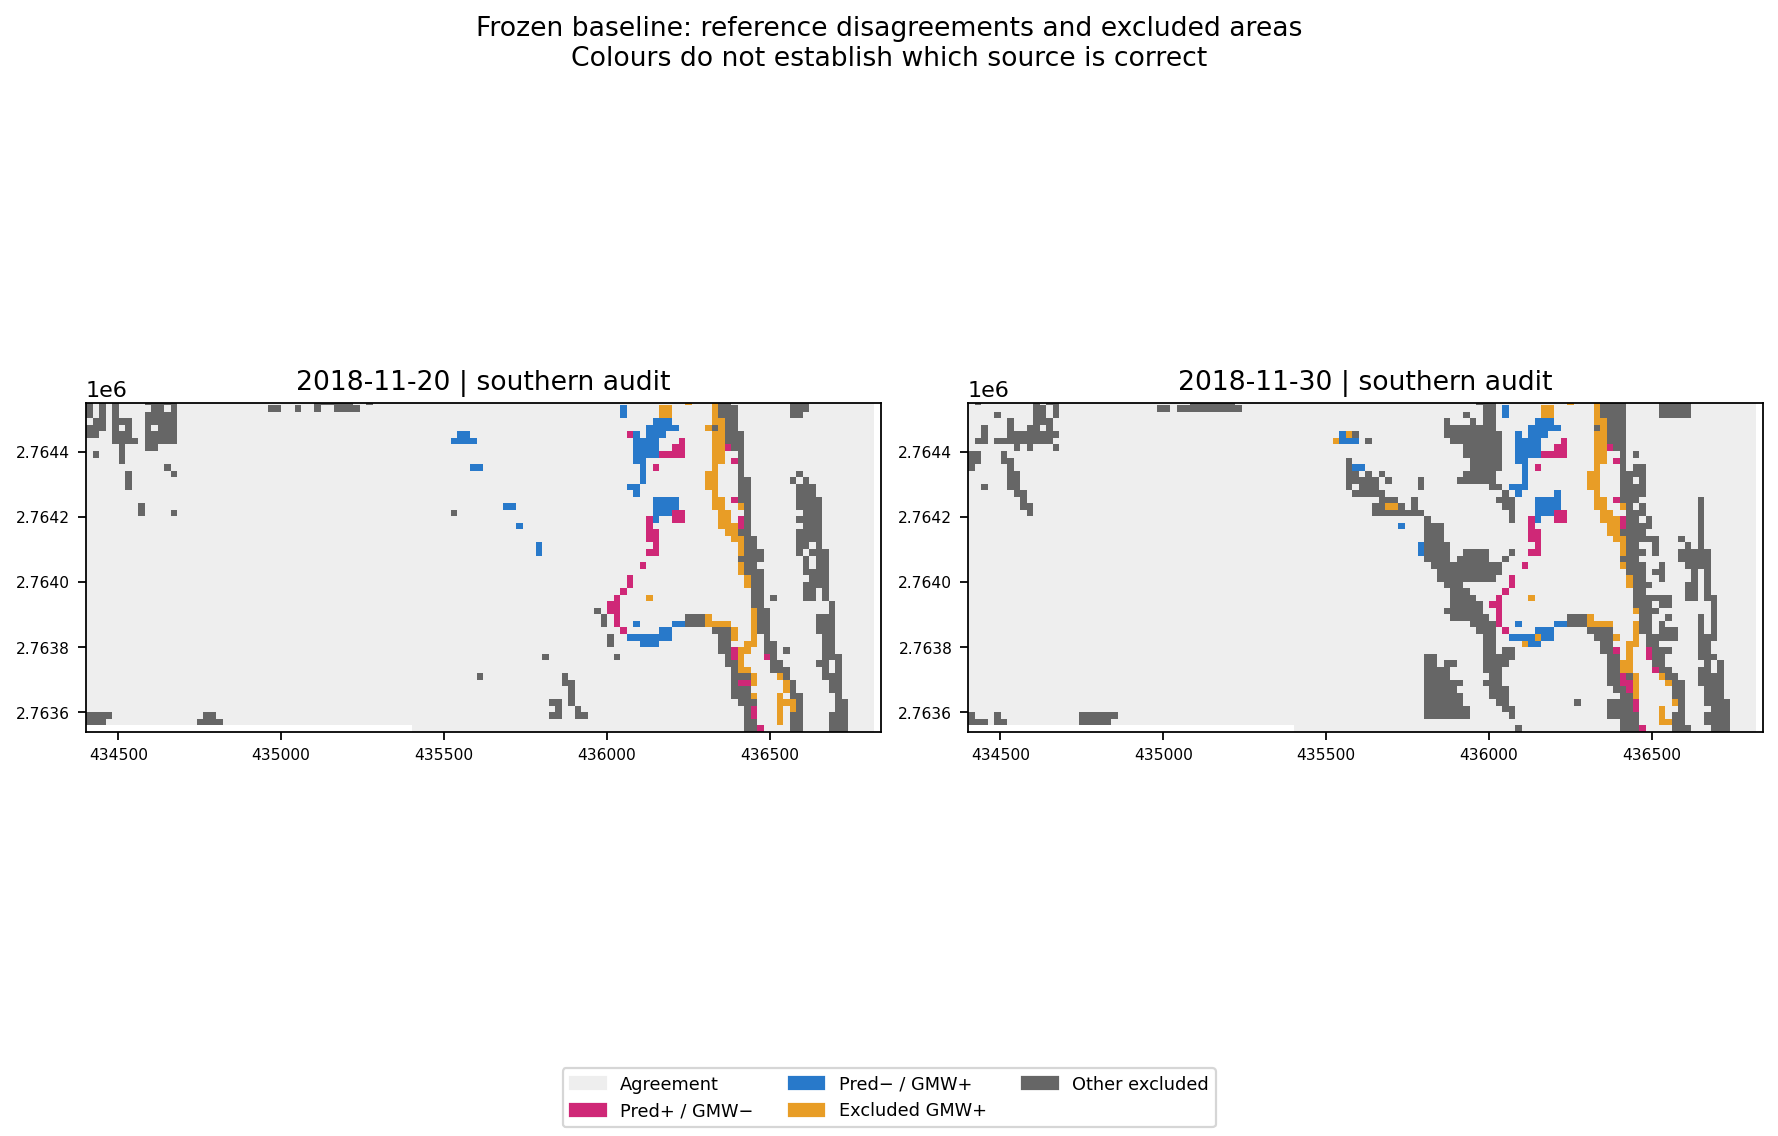

In [3]:
if STATE['status']=='dependencies_ready':
    try:
        REPRO=RUN/'reproduction'
        command([str(PY),str(ROOT/'src/run_submission.py'),'--root',str(ROOT),'--out',str(REPRO)],
                'reproduction_console',750,ENV)
        report=json.loads((REPRO/'run_status.json').read_text())
        if report.get('status')!='succeeded': raise RuntimeError('Runner did not report success')
        STATE.update(status='reproduced',reproduction='succeeded')
        display(Markdown('**RESULT: frozen baseline and audit reproduced and matched.** Not field accuracy.'))
        summary=json.loads((REPRO/'baseline/baseline_summary.json').read_text())
        table=['| Southern reference agreement | Nov 20, 2018 | Nov 30, 2018 |',
               '|---|---:|---:|']
        for label,key in [('Precision','precision'),('Recall','recall'),('F1','f1'),('IoU','iou')]:
            values=[summary['held_out'][d]['all_eligible_southern_cells'][key] for d in ['2018-11-20','2018-11-30']]
            table.append(f'| {label} | {values[0]:.4f} | {values[1]:.4f} |')
        display(Markdown('\n'.join(table)))
        print('Northern calibration F1:',round(summary['calibration']['f1'],4),'— not regional generalization')
        display(Image(filename=str(REPRO/'baseline/baseline_inspection.png'),width=1100))
        display(Image(filename=str(REPRO/'audit/audit_overview.png'),width=1100))
    except Exception as exc:
        STATE.update(status='failed_reproduction_or_display',error=str(exc))
        (RUN/'reproduction_failure.log').write_text(traceback.format_exc())
        print('Reproduction/display failed. Do not use partial files as success:',exc)
else: print('Reproduction skipped: inputs/dependencies failed.')
record()


## 3. Saved reference comparison

The 1 October 2026 reference experiment compares GMW v3 and v4.1.12 for 2018 at all 13,401 AOI centres. This differs from the baseline's eligible southern population. WorldCover 2020 is later context and uses GMW as an auxiliary input. These related maps do not establish independent truth or ecological change.

The figures and counts below come from saved records. The separate GE01 review used imagery dated 5 October 2018, before the Sentinel acquisitions, with unresolved relative alignment. This run does not load that imagery.


SAVED PRIOR RESULT: {
  "both_not_mapped": 11806,
  "v3_only_mapped": 177,
  "v4_only_mapped": 437,
  "both_mapped": 981,
  "centres": 13401,
  "differently_mapped_centres": 614,
  "differently_mapped_fraction": 0.04581747630773823,
  "mapped_jaccard": 0.6150470219435736,
  "interpretation": "Reference-map agreement, not field accuracy or ecological change"
}
Among mapped union: 614 / 1595 differ


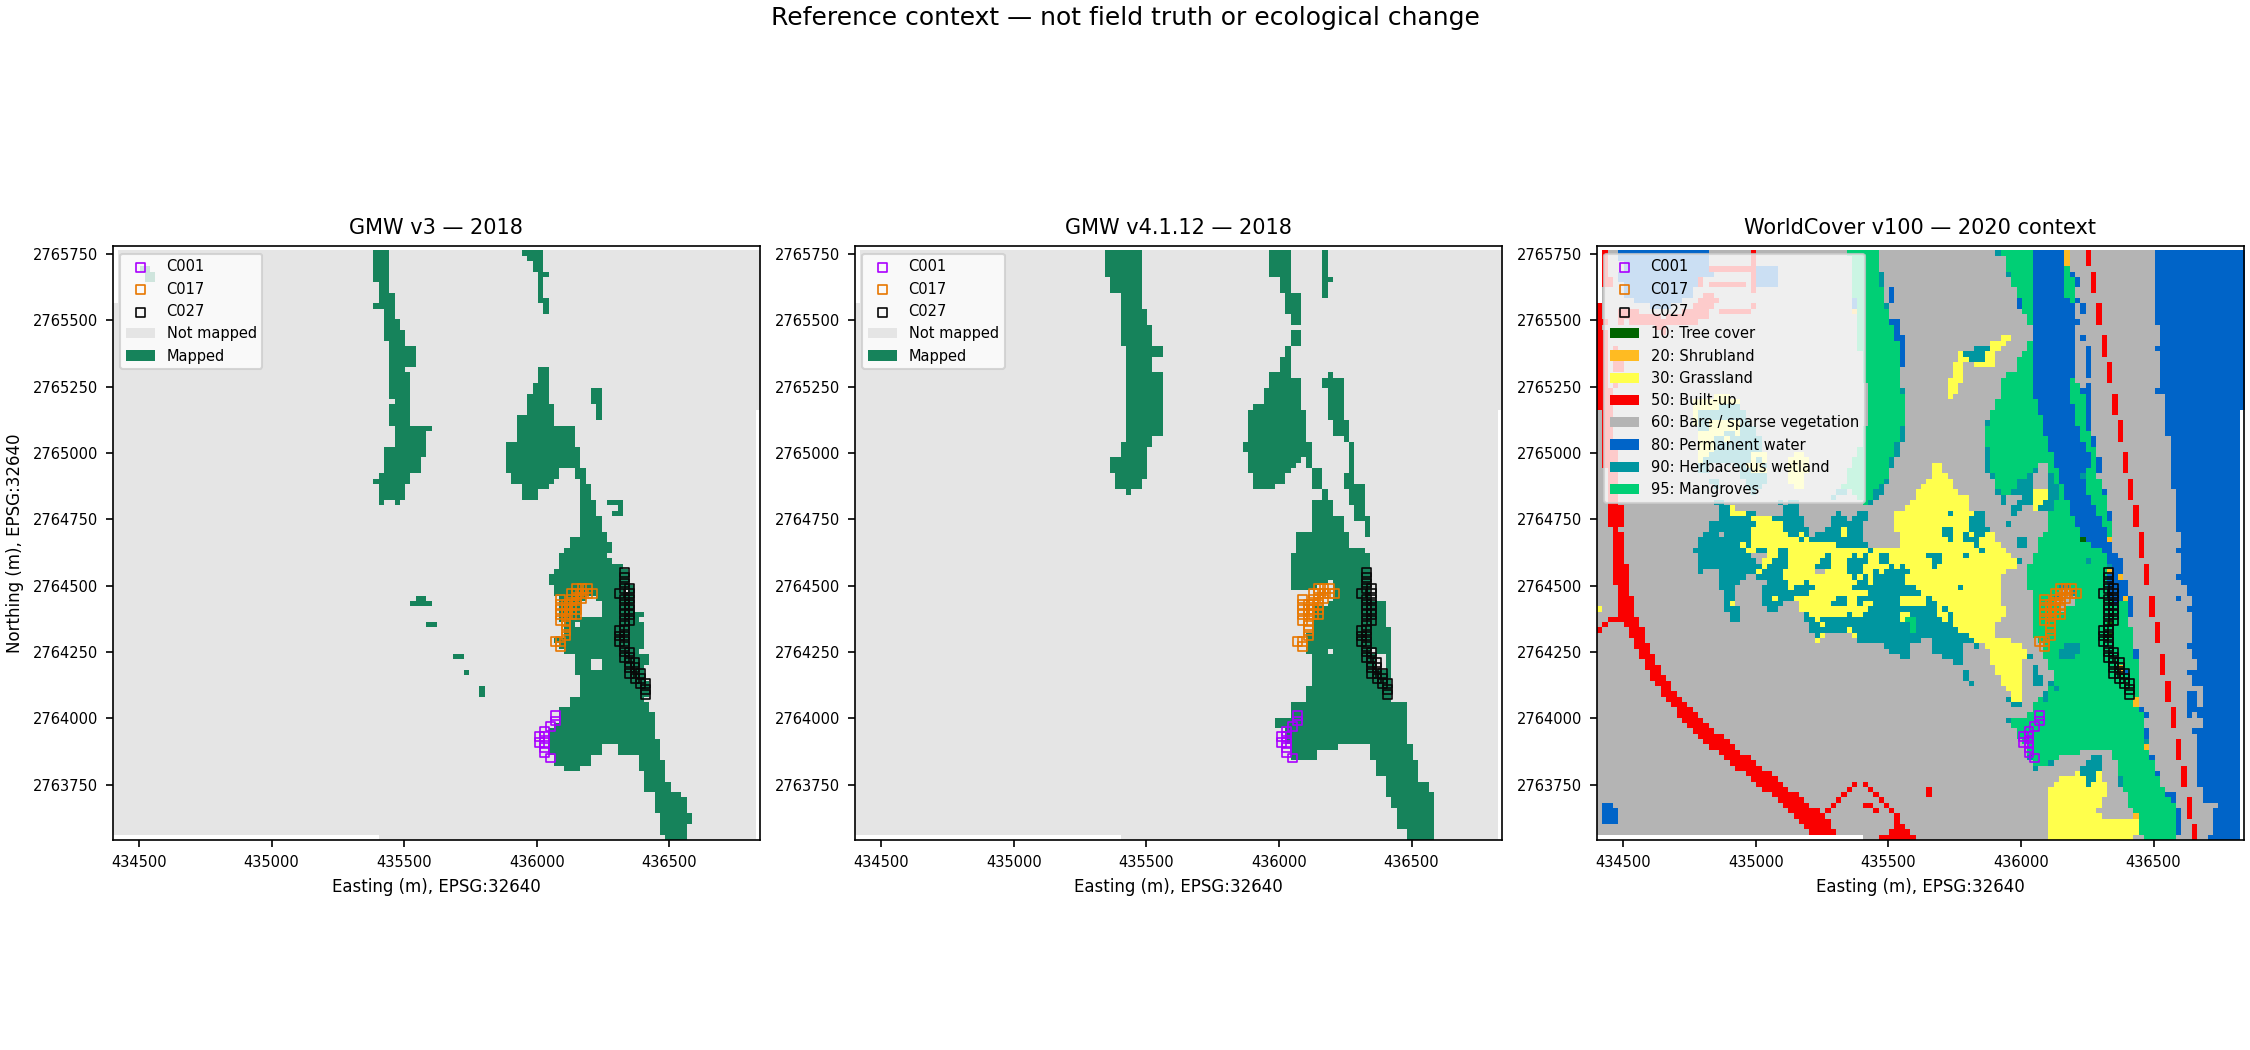

### C001 — Prediction positive / GMW not mapped

**Observation question:** Which target cells and surroundings contain identifiable canopy at the observation date, and how certain is the edge alignment?

**Candidate method:** Existing licensed imagery or safe shore/boat photography; ordinary RGB drone only if access and observation quality justify it

**Amphibious need:** Not established for photographic canopy-edge review

Historical targets: 11; field observations: **0**.

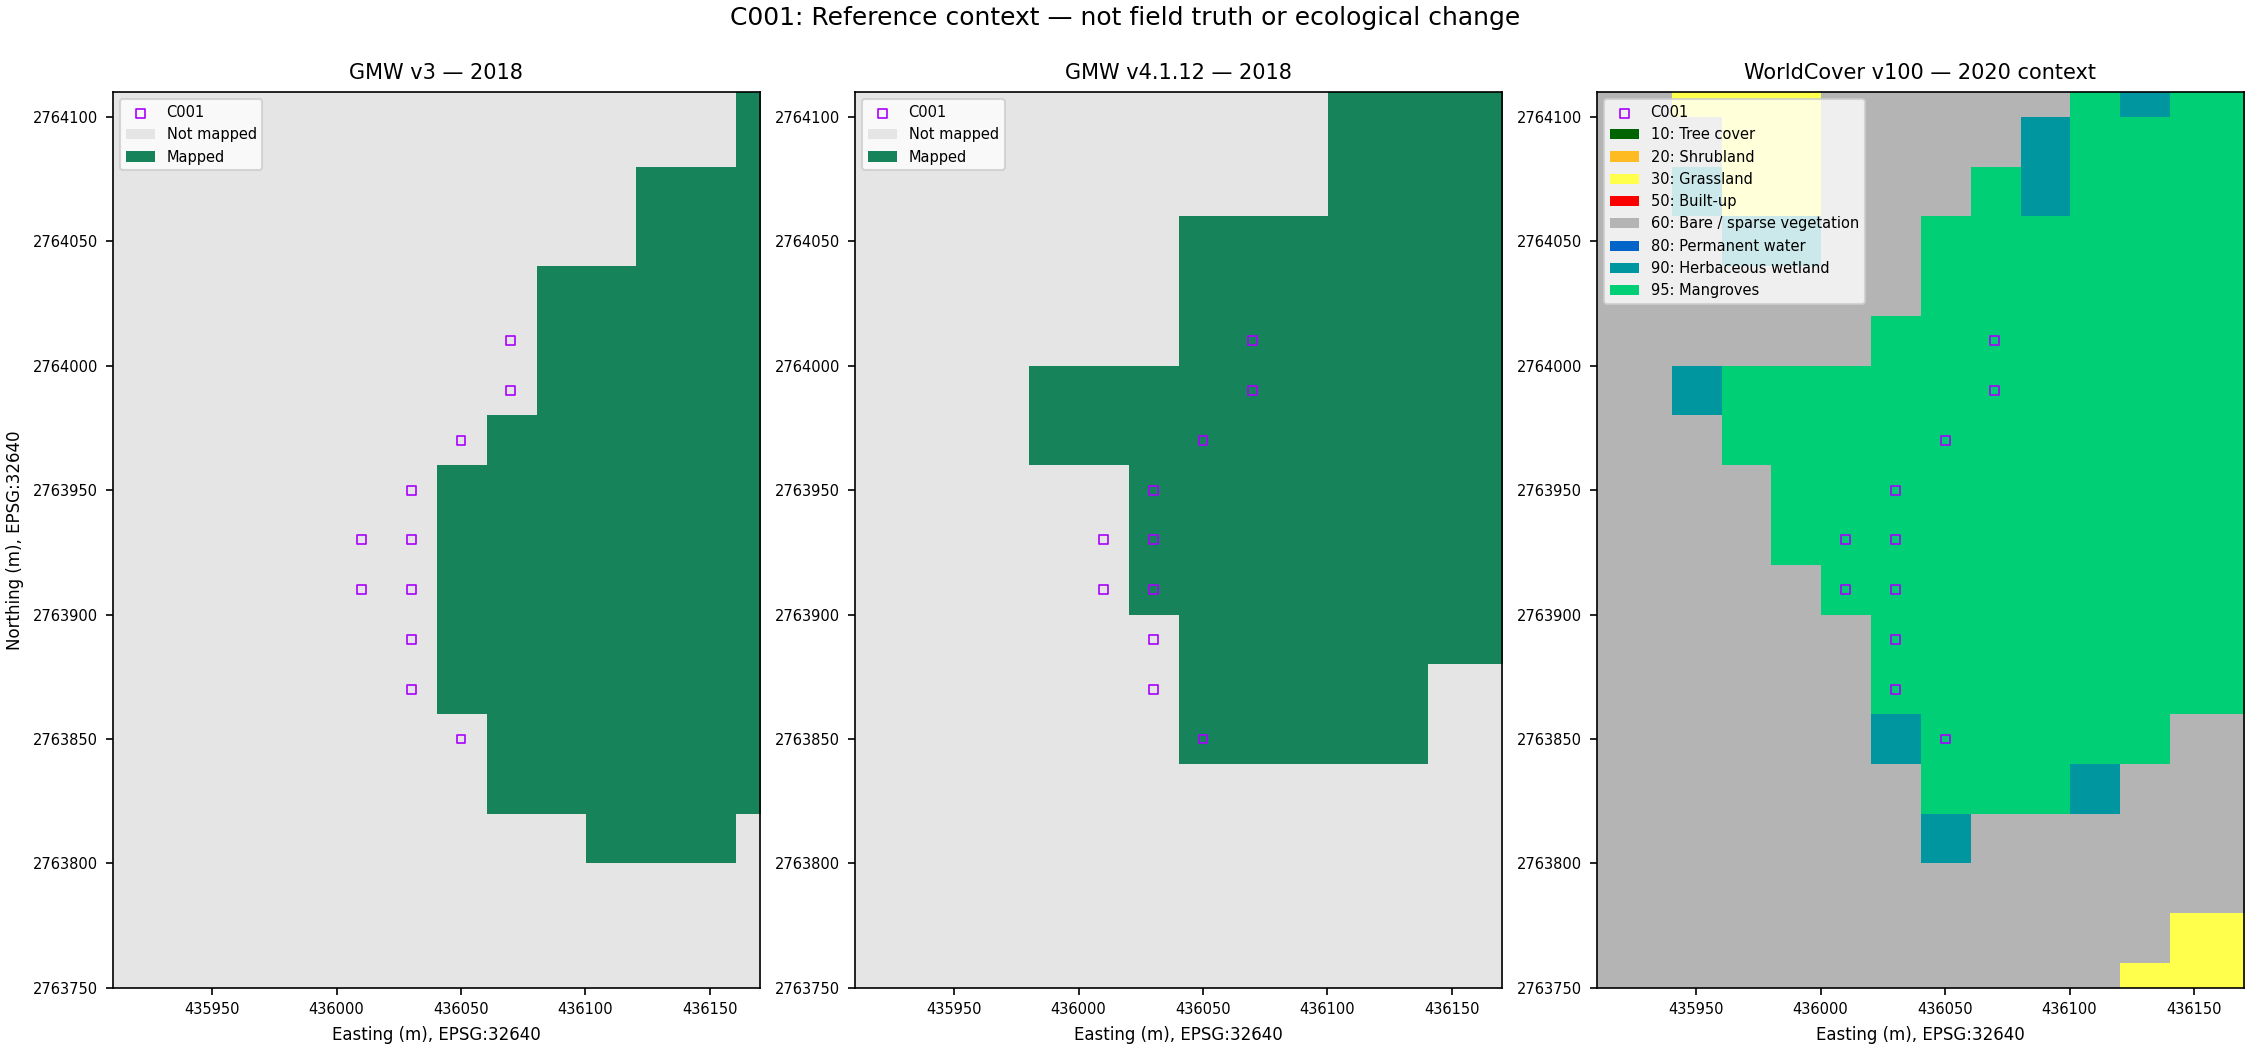

### C017 — Prediction negative / GMW mapped

**Observation question:** What cover composition can be supported for each cell, including mixed vegetation, water and open ground?

**Candidate method:** Detailed licensed imagery, shore/boat photography or ordinary RGB drone where justified

**Amphibious need:** Not established for photographic mixed-cover review

Historical targets: 32; field observations: **0**.

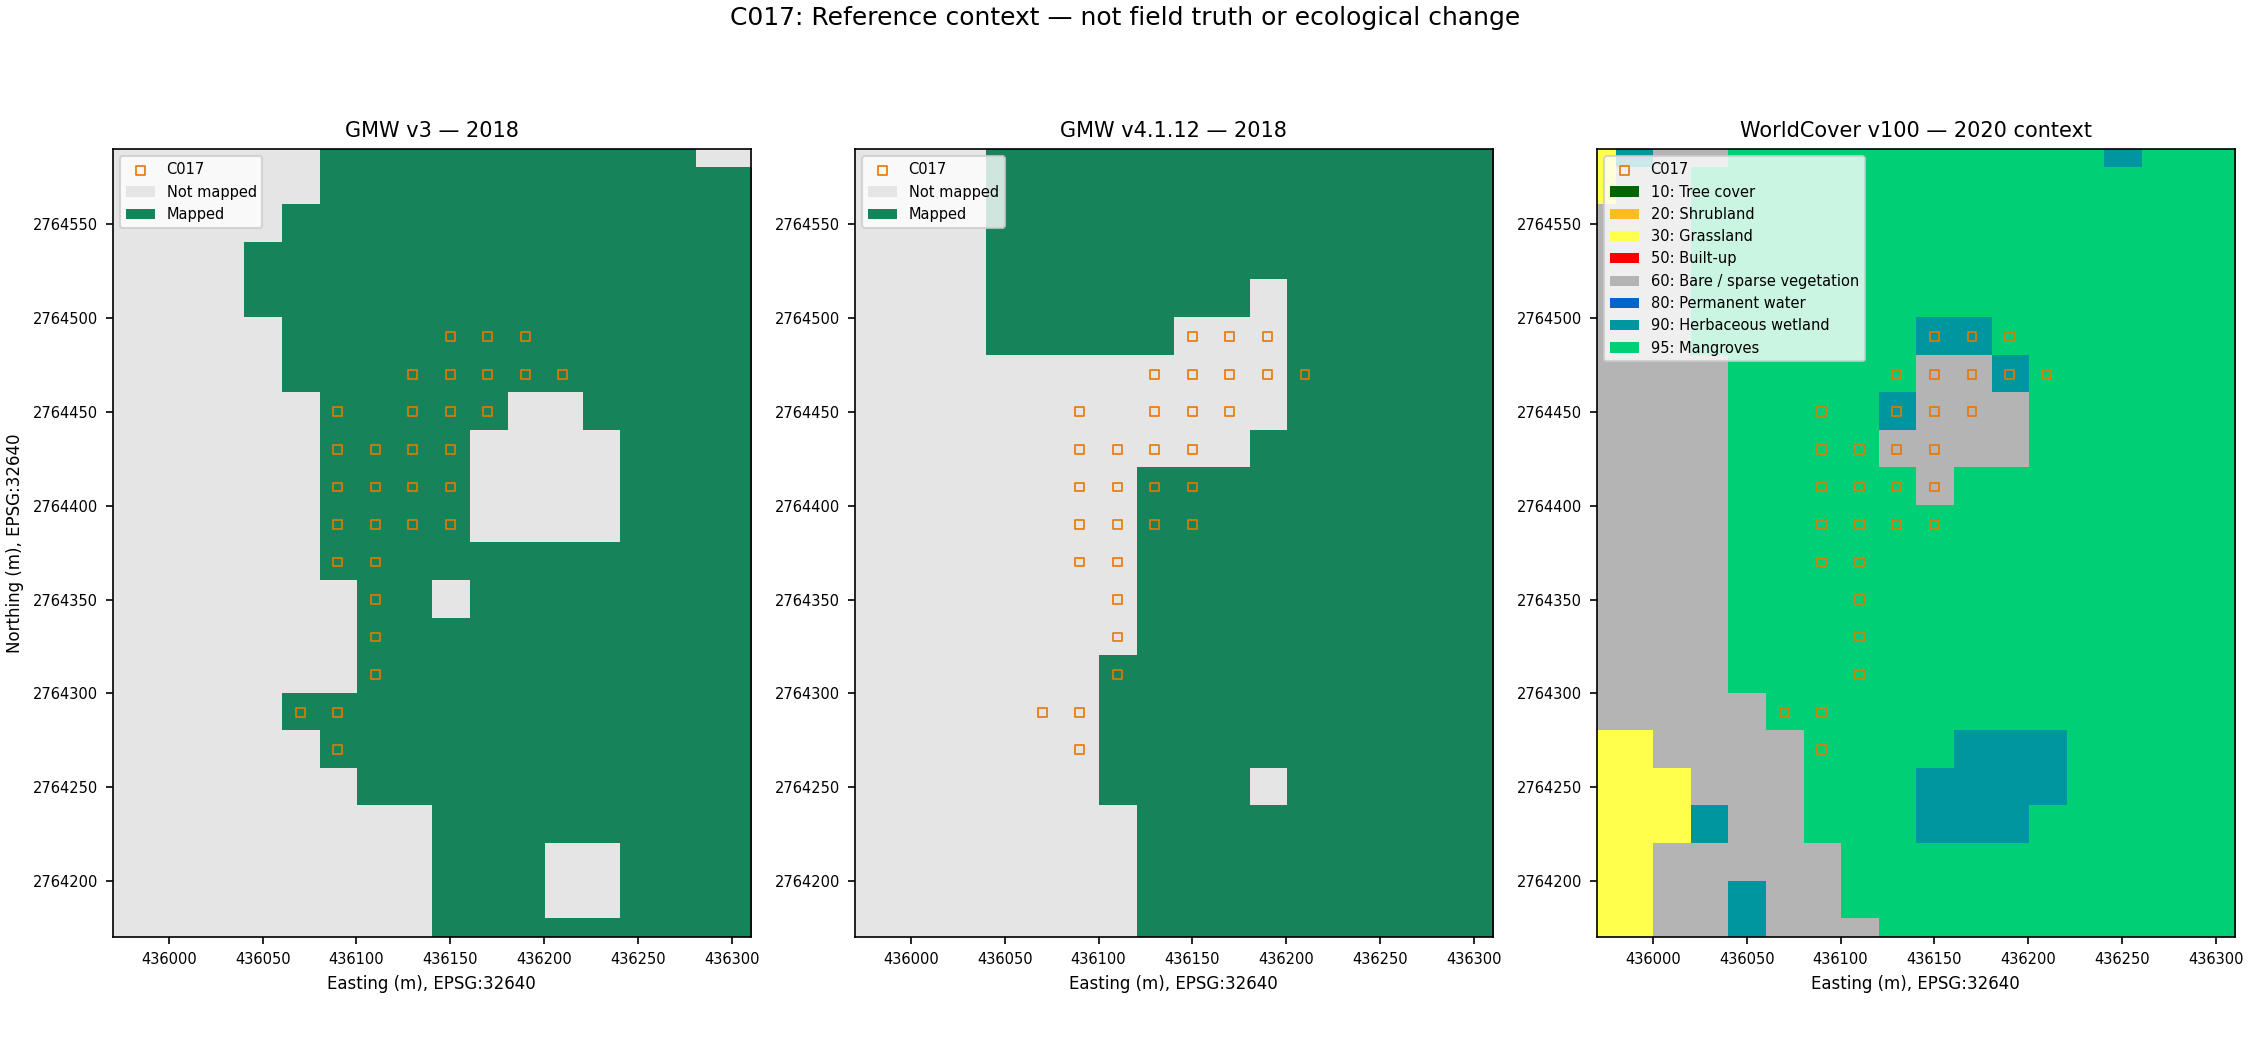

### C027 — Quality-excluded / GMW mapped

**Observation question:** What dated cover evidence is available at the channel margin, and what limits the original usable satellite coverage?

**Candidate method:** Historical source review first; current channel-edge photography only as a separate workflow trial

**Amphibious need:** Conditional separate current contact-sensing hypothesis, not inferred from exclusions

Historical targets: 42; field observations: **0**.

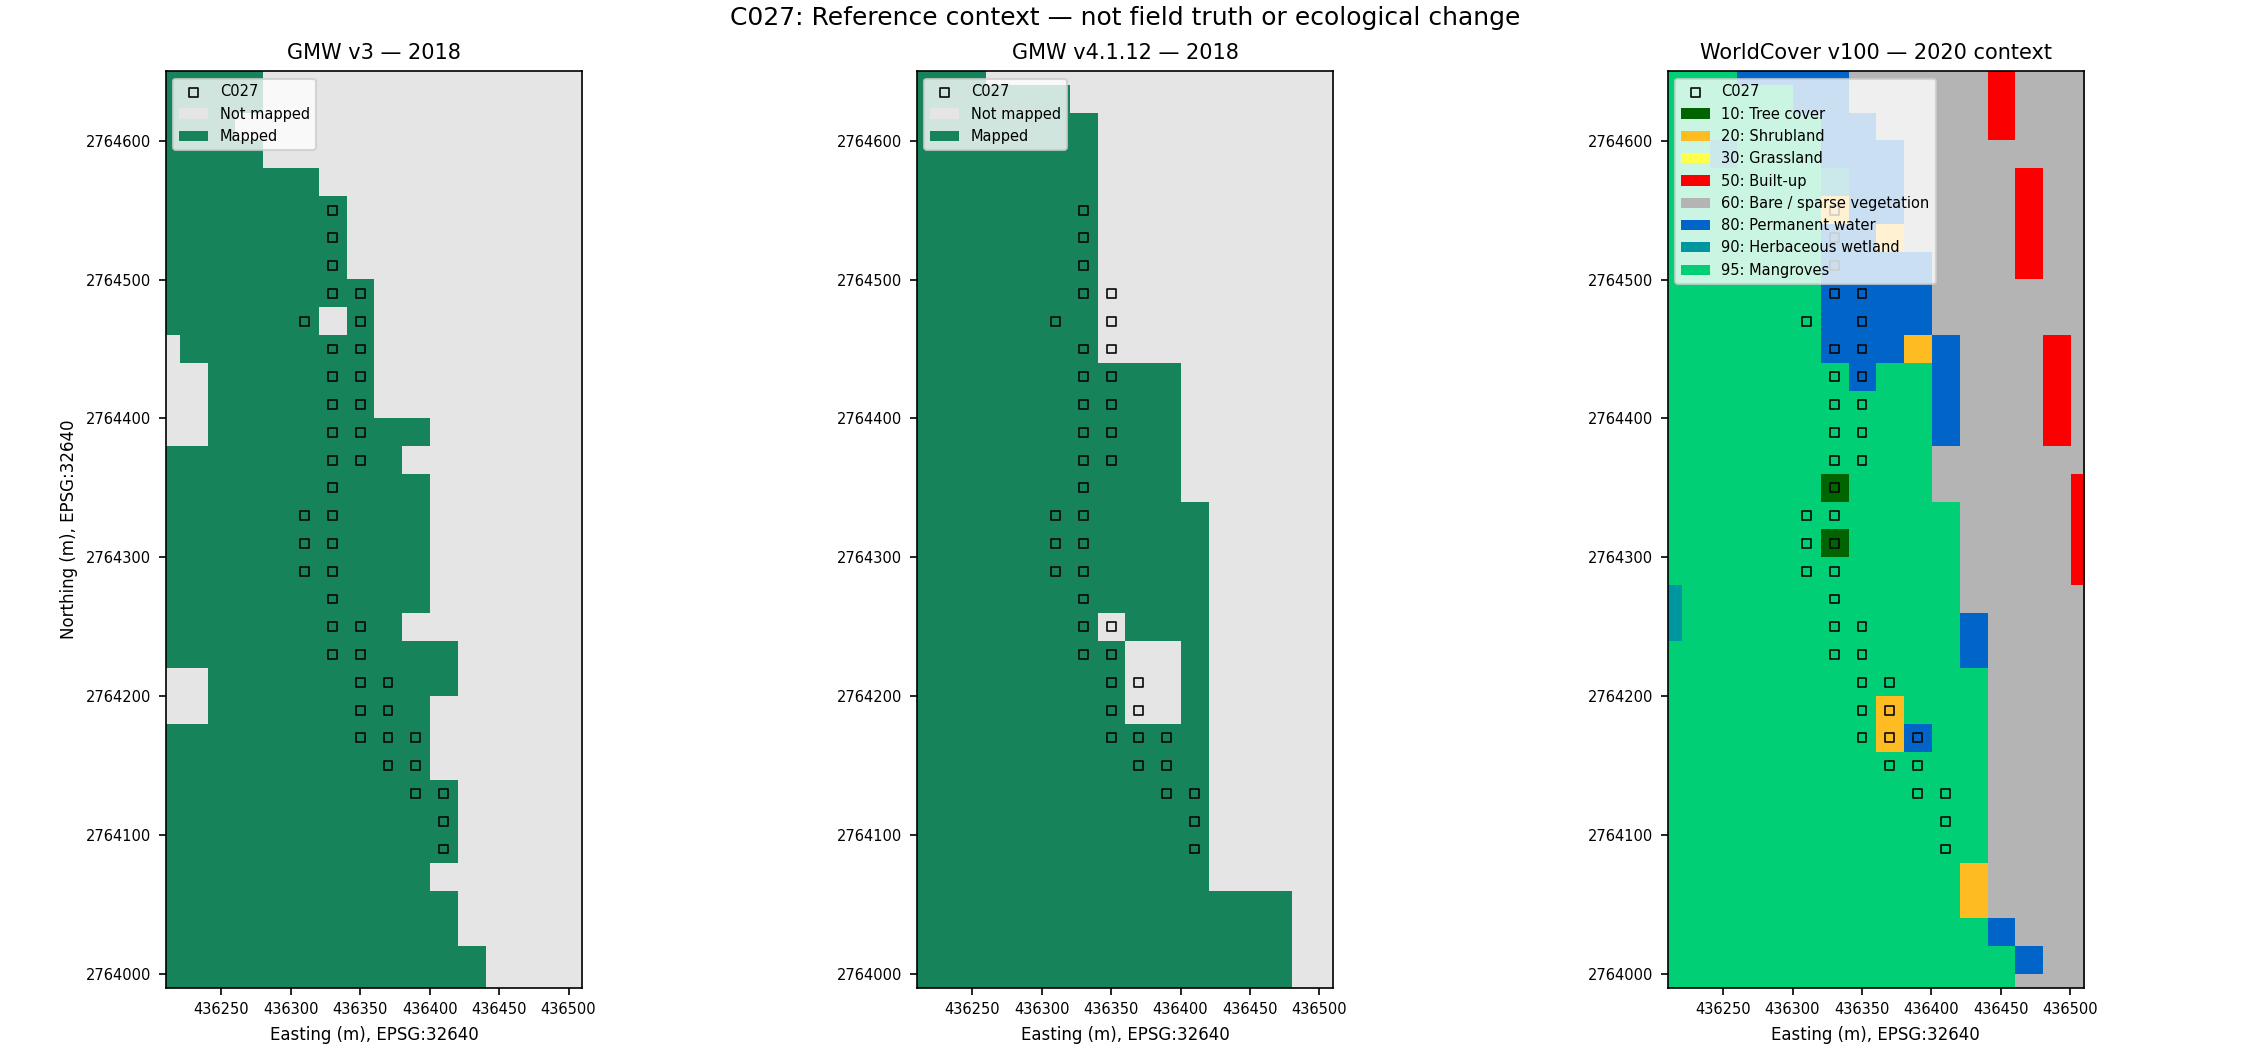

In [4]:
if STATE['reproduction']=='succeeded' and STATE['status']=='reproduced':
    try:
        saved=json.loads((ROOT/'examples/reference_context/comparison_summary.json').read_text())
        context=saved['full_aoi_gmw2018']
        print('SAVED PRIOR RESULT:',json.dumps(context,indent=2))
        union=context['v3_only_mapped']+context['v4_only_mapped']+context['both_mapped']
        print('Among mapped union:',context['differently_mapped_centres'],'/',union,'differ')
        display(Image(filename=str(ROOT/'examples/reference_context/reference_context_overview.png'),width=1100))
        requests=json.loads((ROOT/'examples/inspection/inspection_requests.json').read_text())
        for case in requests['cases']:
            cid=case['case_id']
            display(Markdown('### '+cid+' — '+case['original_category']+'\n\n'+
                '**Observation question:** '+case['question']+'\n\n'+
                '**Candidate method:** '+case['candidate_method']+'\n\n'+
                '**Amphibious need:** '+case['amphibious_need']+'\n\n'+
                'Historical targets: '+str(case['target_count'])+'; field observations: **0**.'))
            display(Image(filename=str(ROOT/f'examples/reference_context/{cid}_reference_context.png'),width=1000))
        STATE['status']='context_displayed'
    except Exception as exc:
        STATE.update(status='failed_context_display',error=str(exc))
        (RUN/'context_failure.log').write_text(traceback.format_exc())
        print('Saved context display failed:',exc)
else: print('Review display skipped: clean reproduction required.')
record()


## 4. Check request metadata and export templates

The software checks the demonstration's request and blank-return format, including coordinates, labels, dates, memberships and safe export paths. It does not validate real field measurements. Targets are historical cell centres, not flight waypoints, landing positions or approved water-contact sites.

The CSV separates target coordinates from observation coordinates; measurement fields are empty. Field access and habitat-disturbance permissions remain unconfirmed. The [C001 brief](docs/C001_INSPECTION_BRIEF.md) supplies proposed evidence-acceptance and decision rules, not completed observations.


In [5]:
if STATE['status']=='context_displayed':
    try:
        TEST_TMP=RUN/'format_test_tmp'; TEST_TMP.mkdir()
        test_env=ENV.copy(); test_env['MP_FORMAT_TEST_TMP']=str(TEST_TMP)
        command([str(PY),'-B','-m','unittest','discover','-s',str(ROOT/'tests'),'-p',
                 'test_inspection_handoff.py','-v'],'handoff_format_tests',120,test_env)
        command([str(PY),str(ROOT/'src/inspection_handoff.py'),'--root',str(ROOT),
                 '--out',str(RUN/'inspection_export')],'inspection_export',120,ENV)
        validation=json.loads((RUN/'inspection_export/validation.json').read_text())
        if validation.get('status')!='format_and_traceability_passed': raise RuntimeError('Handoff did not pass')
        STATE.update(status='handoff_verified',handoff='format_and_traceability_passed')
        print(json.dumps(validation,indent=2))
        display(Markdown('**85 historical centres exported; zero collected observations.**\n\n'+
            'Files: inspection requests, GeoJSON, blank JSON return template, '+
            '85-row observations_UNFILLED.csv, attribution and validation record.'))
    except Exception as exc:
        STATE.update(status='failed_handoff',error=str(exc))
        (RUN/'handoff_failure.log').write_text(traceback.format_exc())
        print('Handoff failed:',exc)
else: print('Export skipped: clean reproduction and context display required.')
record()


test_context_change_rejected (test_inspection_handoff.HandoffTests.test_context_change_rejected) ... ok
test_coordinate_change_rejected (test_inspection_handoff.HandoffTests.test_coordinate_change_rejected) ... ok
test_date_change_rejected (test_inspection_handoff.HandoffTests.test_date_change_rejected) ... ok
test_duplicate_target_rejected (test_inspection_handoff.HandoffTests.test_duplicate_target_rejected) ... ok
test_export_empty_csv_and_source_identity (test_inspection_handoff.HandoffTests.test_export_empty_csv_and_source_identity) ... ok
test_fabricated_conclusion_rejected (test_inspection_handoff.HandoffTests.test_fabricated_conclusion_rejected) ... ok
test_flight_waypoint_claim_rejected (test_inspection_handoff.HandoffTests.test_flight_waypoint_claim_rejected) ... ok
test_missing_case_membership_rejected (test_inspection_handoff.HandoffTests.test_missing_case_membership_rejected) ... ok
test_no_overwrite (test_inspection_handoff.HandoffTests.test_no_overwrite) ... ok
test_origi

**85 historical centres exported; zero collected observations.**

Files: inspection requests, GeoJSON, blank JSON return template, 85-row observations_UNFILLED.csv, attribution and validation record.

## 5. Conditional platform tradeoffs

The saved energy study assumes three hypothetical sites, unrelated to the three Kalba cases. At 150 seconds dwell per site it estimates about 170.7 Wh for hover and 128.0 Wh for supported sensing, roughly 25% lower energy but longer elapsed time. Break-even is about 84.2 seconds under those inputs. Short dwell or added overhead reverses the energy comparison. Observation quality, transitions, recovery and energy consumption remain unmeasured.

First define an authorized observation task and test sensor quality using the simplest feasible method. Then compare complete resources per accepted observation, failures, recovery and habitat disturbance against shore, boat, logger, USV and ordinary-drone alternatives where they answer the same question. The [current assessment](docs/CONNECTED_CONCEPT_ASSESSMENT.md) explains the necessary tests. This model does not demonstrate aircraft superiority.


In [6]:
if STATE['status']=='handoff_verified':
    try:
        energy=json.loads((ROOT/'examples/inspection/energy_scenario_excerpt.json').read_text())
        rows=['| Saved hypothetical case | Hover Wh | Supported Wh | Supported lower? |',
              '|---|---:|---:|---|']
        for name,case in energy['illustrative_cases'].items():
            r=case['result']
            rows.append(f"| {name} | {r['hover_energy_wh']:.1f} | {r['supported_energy_wh']:.1f} | {r['supported_energy_lower']} |")
        display(Markdown('\n'.join(rows)))
        print('SAVED RESULT ONLY — no aircraft/model execution in this notebook.')
        print('Observation equivalence and operational feasibility: NOT ESTABLISHED.')
        STATE['status']='succeeded'
    except Exception as exc:
        STATE.update(status='failed_energy_display',error=str(exc))
        (RUN/'energy_display_failure.log').write_text(traceback.format_exc())
        print('Saved energy display failed:',exc)
else: print('Conditional-energy display skipped: handoff did not pass.')
record()


| Saved hypothetical case | Hover Wh | Supported Wh | Supported lower? |
|---|---:|---:|---|
| short_dwell | 88.8 | 124.0 | False |
| illustrative_main | 170.7 | 128.0 | True |
| long_dwell | 273.2 | 133.0 | True |
| long_route_energy_only_win | 478.1 | 416.9 | True |
| extra_80_wh_overhead | 170.7 | 208.0 | False |

SAVED RESULT ONLY — no aircraft/model execution in this notebook.
Observation equivalence and operational feasibility: NOT ESTABLISHED.


## 6. Recorded run status and export

The final cell packages logs and status. A successful status records completed reproduction and template handling, not field accuracy, ecological need or drone performance. Saved context and hypothetical calculations remain separate from reproduced outputs.

The original integrated results ZIP was not recovered locally; its integrity is unverified. The actual notebook execution and visible outputs are preserved.


In [7]:
STATE['finished_utc']=datetime.now(timezone.utc).isoformat()
record()
review=RUN/'review_docs'; review.mkdir(exist_ok=True)
if 'ROOT' in globals() and ROOT is not None and ROOT.is_dir():
    for name in ['DRONE_KHOR_KALBA_HANDOFF.md','POC_LOGIC_AND_NEXT_STEP.md',
                 'C001_INSPECTION_BRIEF.md','C017_INSPECTION_BRIEF.md','C027_INSPECTION_BRIEF.md']:
        p=ROOT/'docs'/name
        if p.is_file(): (review/name).write_bytes(p.read_bytes())
    attribution=ROOT/'ATTRIBUTION.md'
    if attribution.is_file(): (review/'ATTRIBUTION.md').write_bytes(attribution.read_bytes())
    if STATE['status']=='succeeded':
        context_out=RUN/'saved_prior_reference_context'; context_out.mkdir(exist_ok=True)
        for p in (ROOT/'examples/reference_context').iterdir():
            if p.suffix=='.png' or p.name in ['comparison_summary.json','case_comparison.json','run_status.json','METHOD.md','ATTRIBUTION.md']:
                (context_out/p.name).write_bytes(p.read_bytes())
        (RUN/'saved_hypothetical_energy.json').write_bytes((ROOT/'examples/inspection/energy_scenario_excerpt.json').read_bytes())
    pins=ROOT/'requirements.txt'
    if pins.is_file(): (RUN/'dependency_pins.txt').write_bytes(pins.read_bytes())
payload=[]
for p in RUN.rglob('*'):
    if not p.is_file(): continue
    relative=p.relative_to(RUN)
    if relative.parts[0] in ['venv','repository','mplconfig','format_test_tmp'] or p.name in ['repository.zip','output_manifest.json']: continue
    payload.append(p)
manifest={p.relative_to(RUN).as_posix():hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(payload)}
(RUN/'output_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
archive=RUN.parent/(RUN.name+'_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(payload)+[RUN/'output_manifest.json']: z.write(p,p.relative_to(RUN))
print('STATUS:',STATE['status'])
print('ZIP:',archive.name,'bytes:',archive.stat().st_size,'SHA-256:',hashlib.sha256(archive.read_bytes()).hexdigest())
print('Manifest excludes itself. No observation or drone operational validation is claimed.')
if STATE['status']!='succeeded': print('DIAGNOSTICS ONLY. Return ZIP for repair; do not call this completed results.')
try:
    from google.colab import files
    files.download(str(archive))
except ImportError: print('Outside Colab; result ZIP is at:',archive)


STATUS: succeeded
ZIP: mangrove_pulse_end_to_end_fz8cmpr8_results.zip bytes: 2080621 SHA-256: f1c9ddb95cc98a8bb35090648fd49d616317937ee52cc2c0745b828b44947f2a
Manifest excludes itself. No observation or drone operational validation is claimed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>